In [113]:
from pylibCZIrw import czi as pyczi
import matplotlib.pyplot as plt 
import matplotlib.cm as cm
import numpy as np
from skimage import feature
from skimage.morphology import opening, disk
from skimage.filters import median
from skimage.morphology import skeletonize
from skimage.morphology import disk, white_tophat, dilation, remove_small_objects
from skimage.transform import probabilistic_hough_line
from skimage import exposure

filepath = "data/x63 bmi tubulin iii_data/New-08.czi"

# open the CZI document
with pyczi.open_czi(filepath) as czidoc:

    # read a 2D image plane and specify plane coordinates
    image2d = czidoc.read(plane={"T": 1, "Z": 2, "C": 0})

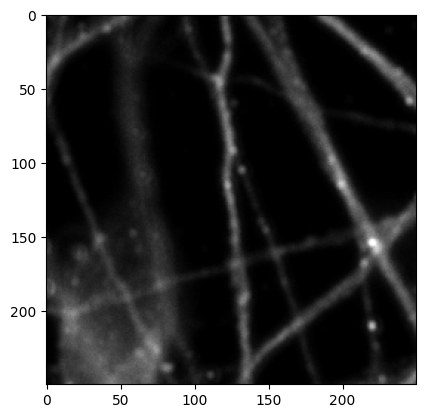

In [114]:
patch_1 = np.copy(image2d[150:400, 50:300])
plt.imshow(patch_1, cmap='gray')

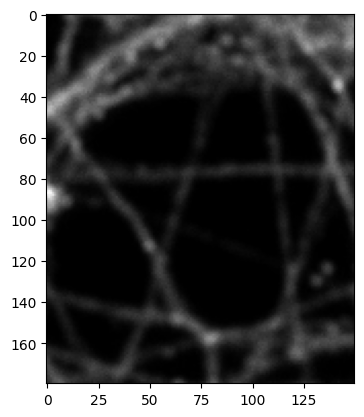

In [115]:
patch_2 = np.copy(image2d[920:1100, 900:1050])
plt.imshow(patch_2, cmap='gray')

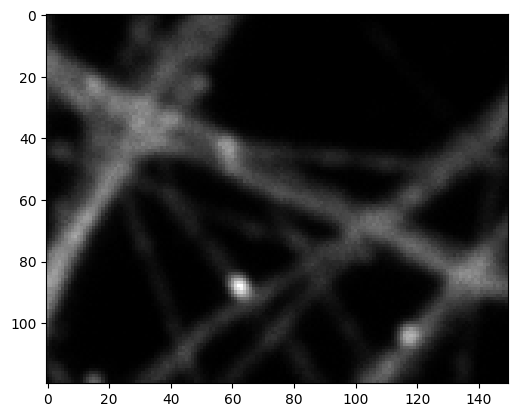

In [116]:
patch_3 = np.copy(image2d[1400:1520, 850:1000])
plt.imshow(patch_3, cmap='gray')

# Skeleton Analysis

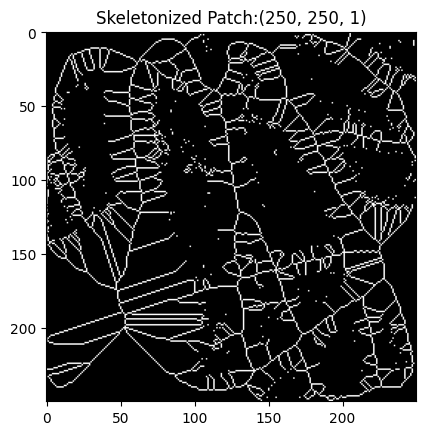

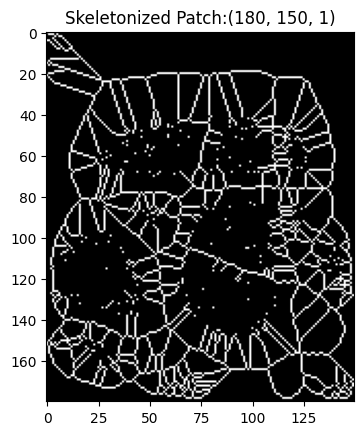

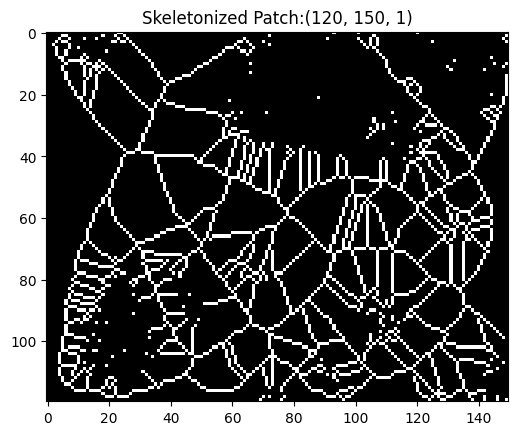

In [117]:
for patch in [patch_1, patch_2, patch_3]:

    skeleton = skeletonize(patch)
    plt.figure()
    plt.imshow(skeleton, cmap="gray")
    plt.title("Skeletonized Patch:" + str(patch.shape))

# Hough Lines

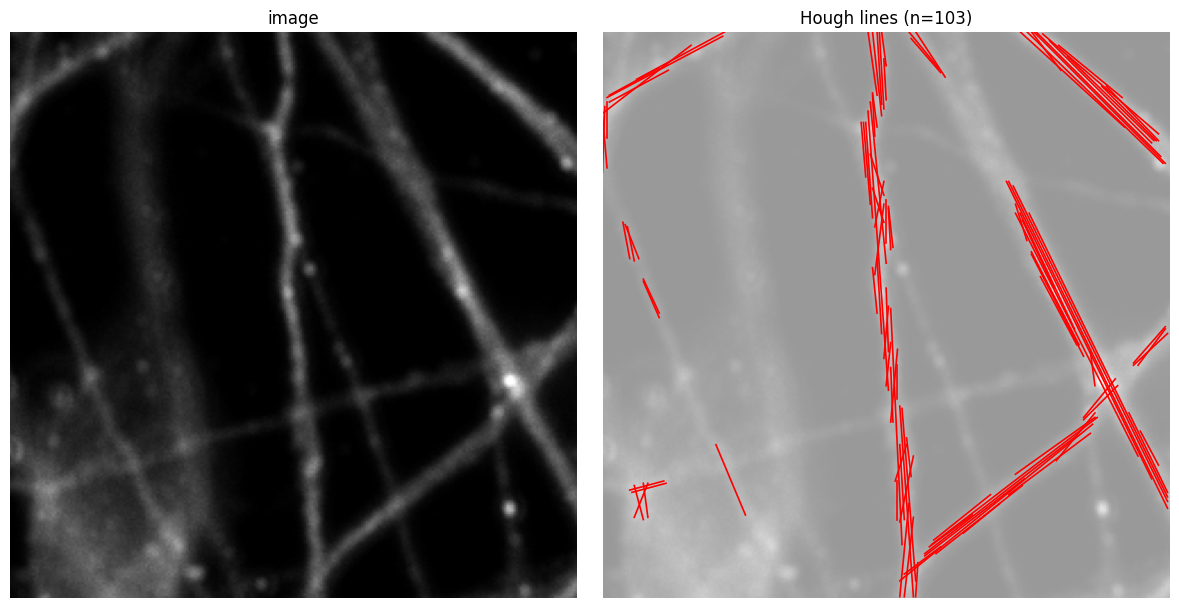

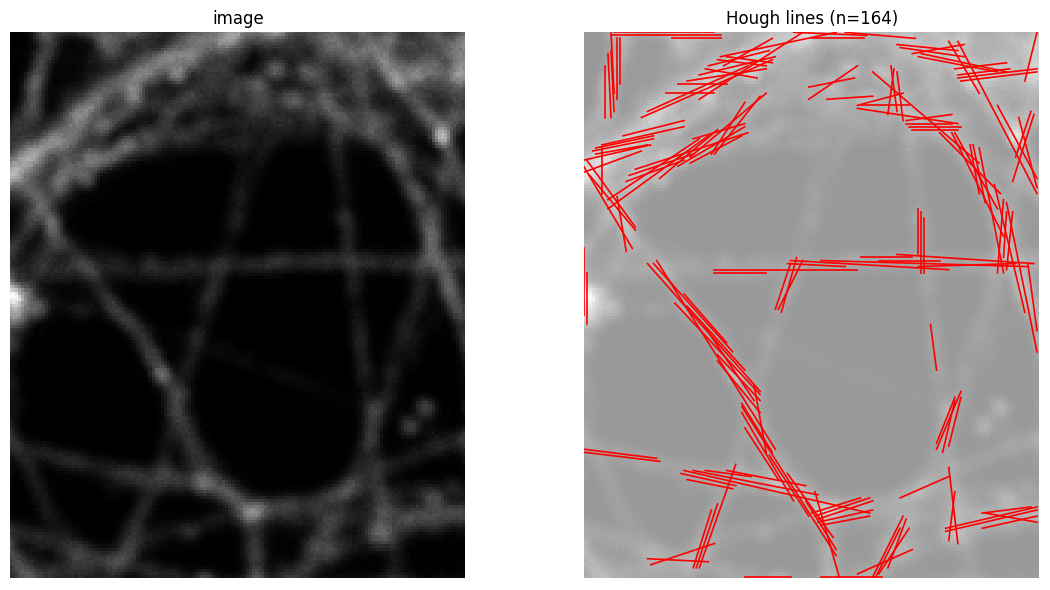

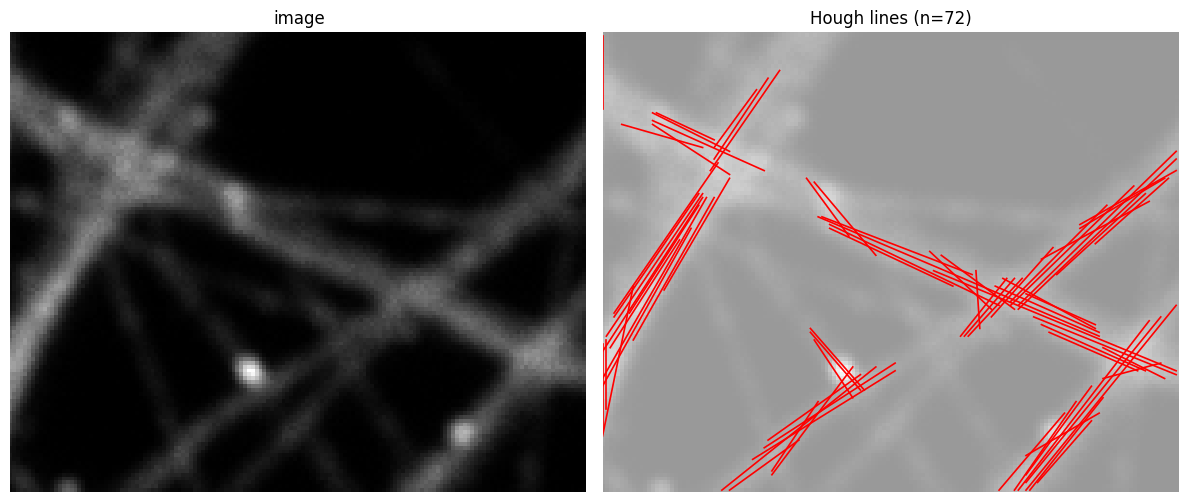

In [118]:
def show_hough_lines(img,tophat_radius=6, threshold=10, line_length=15, line_gap=3):
    """Detect straight segments per z-plane and show raw image | line map side by side.

    Thin bright tubes are enhanced with a white top-hat, thresholded (Otsu), then fed to
    the probabilistic Hough transform. Left panel = raw plane, right panel = detected
    lines drawn over a dim copy of the same plane.
    """
    from skimage.filters import threshold_otsu

    selem = disk(tophat_radius)

    th   = white_tophat(img, selem)                 # bring out thin bright structures
    mask = th > threshold_otsu(th) if th.max() > 0 else th > 0
    lines = probabilistic_hough_line(mask, threshold=threshold,
                                         line_length=line_length, line_gap=line_gap)

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'{"image"}')

    ax[1].imshow(img, cmap='gray', alpha=0.4)
    for (x0, y0), (x1, y1) in lines:
            ax[1].plot((x0, x1), (y0, y1), color='red', lw=1.2)
    ax[1].set_title(f'Hough lines (n={len(lines)})')

    for a in ax:
            a.set_xlim(0, img.shape[1]); a.set_ylim(img.shape[0], 0)
            a.axis('off')
    plt.tight_layout()
    plt.show()


for patch in [patch_1, patch_2, patch_3]:

    show_hough_lines(patch[:,:,0], tophat_radius=6, threshold=10, line_length=15, line_gap=3)

# Canny

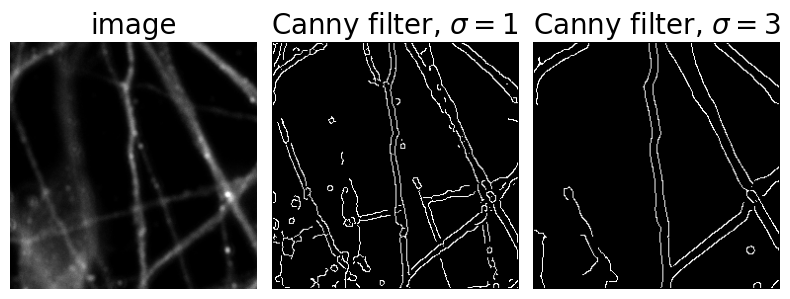

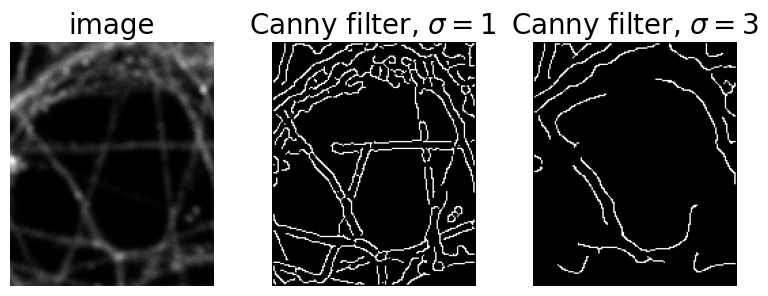

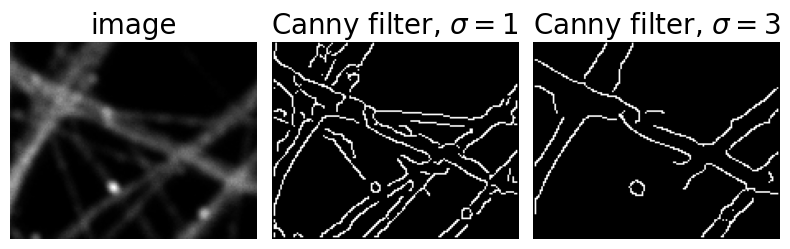

In [119]:
for patch in [patch_1, patch_2, patch_3]:
    edges1 = feature.canny(patch[:,:, 0])
    edges2 = feature.canny(patch[:,:, 0], sigma=3)

    # display results
    fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(8, 3))

    ax[0].imshow(patch[:,:, 0], cmap='gray')
    ax[0].set_title('image', fontsize=20)
 
    ax[1].imshow(edges1, cmap='gray')
    ax[1].set_title(r'Canny filter, $\sigma=1$', fontsize=20)

    ax[2].imshow(edges2, cmap='gray')
    ax[2].set_title(r'Canny filter, $\sigma=3$', fontsize=20)

    for a in ax:
      a.axis('off')

    fig.tight_layout()
    plt.show()

# microscope preprocessing

In [120]:
def preprocessing(img):
    D  = opening(img, disk(6))     # smooth background estimate
    I1 = img - D                   # background-subtracted

    I2 = median(I1, disk(3))           # denoise (median filter)
    p2, p98 = np.percentile(I2, (2, 98))
    img_rescale = exposure.rescale_intensity(I2, in_range=(p2, p98))
    return img_rescale

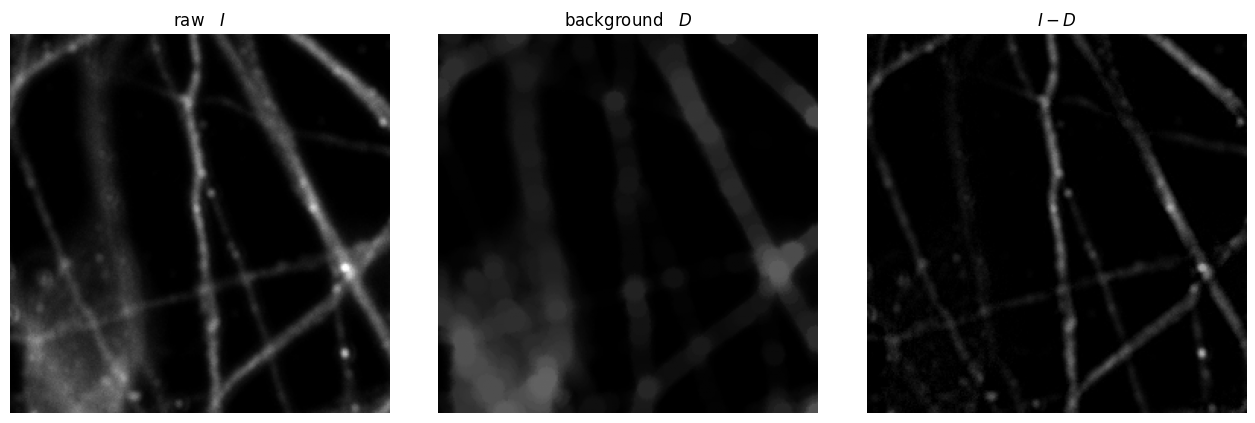

In [121]:
D  = opening(patch_1[:,:,0], disk(6))     # smooth background estimate
I1 = patch_1[:,:,0] - D                   # background-subtracted

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
ax[0].imshow(patch_1[:,:,0], vmin=0, vmax=255, cmap='gray'); ax[0].set_title("raw   $I$")
ax[1].imshow(D,   vmin=0, vmax=255, cmap='gray'); ax[1].set_title("background   $D$")
ax[2].imshow(I1,  vmin=0,  vmax=255, cmap='gray');  ax[2].set_title("$I - D$")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

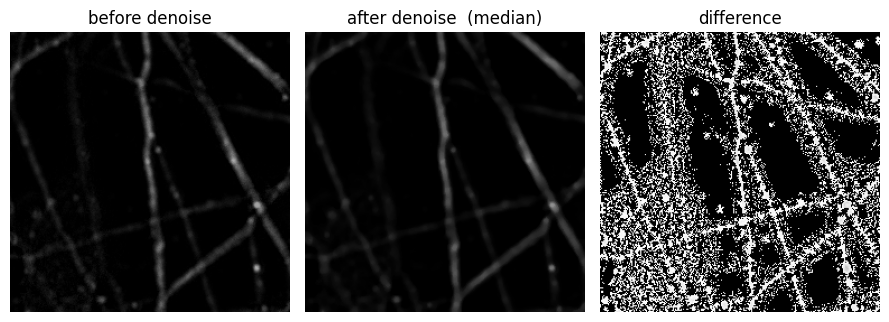

In [122]:
I2 = median(I1, disk(3))
fig, ax = plt.subplots(1, 3, figsize=(9, 4.6))
ax[0].imshow(I1, vmin=0, vmax=255, cmap='gray'); ax[0].set_title("before denoise")
ax[1].imshow(I2, vmin=0, vmax=255, cmap='gray'); ax[1].set_title("after denoise  (median)")
ax[2].imshow(I2-I1, vmin=0, vmax=255, cmap='gray'); ax[2].set_title("difference")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

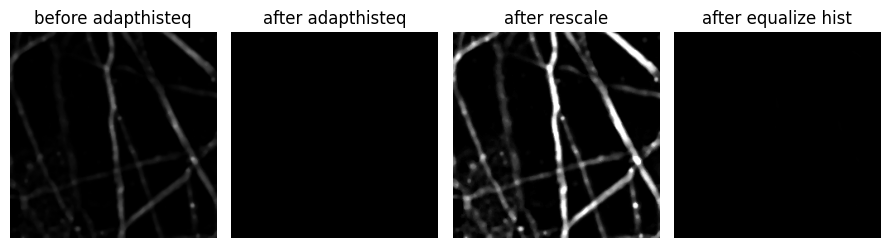

In [123]:
p2, p98 = np.percentile(I2, (2, 98))

img_adapteq = exposure.equalize_adapthist(I2, clip_limit=0.03)
img_rescale = exposure.rescale_intensity(I2, in_range=(p2, p98))
img_eq = exposure.equalize_hist(I2)
fig, ax = plt.subplots(1, 4, figsize=(9, 4.6))
ax[0].imshow(I2, vmin=0, vmax=255, cmap='gray'); ax[0].set_title("before adapthisteq")
ax[1].imshow(img_adapteq, vmin=0, vmax=255, cmap='gray'); ax[1].set_title("after adapthisteq")
ax[2].imshow(img_rescale, vmin=0, vmax=255, cmap='gray'); ax[2].set_title("after rescale")
ax[3].imshow(img_eq, vmin=0, vmax=255, cmap='gray'); ax[3].set_title("after equalize hist")

for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

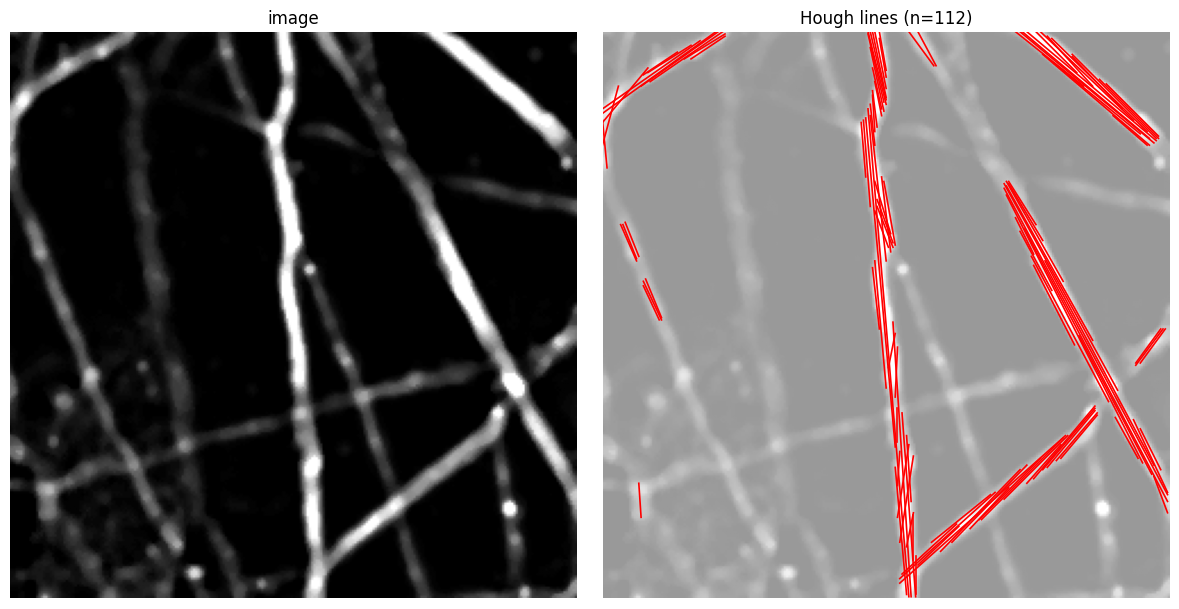

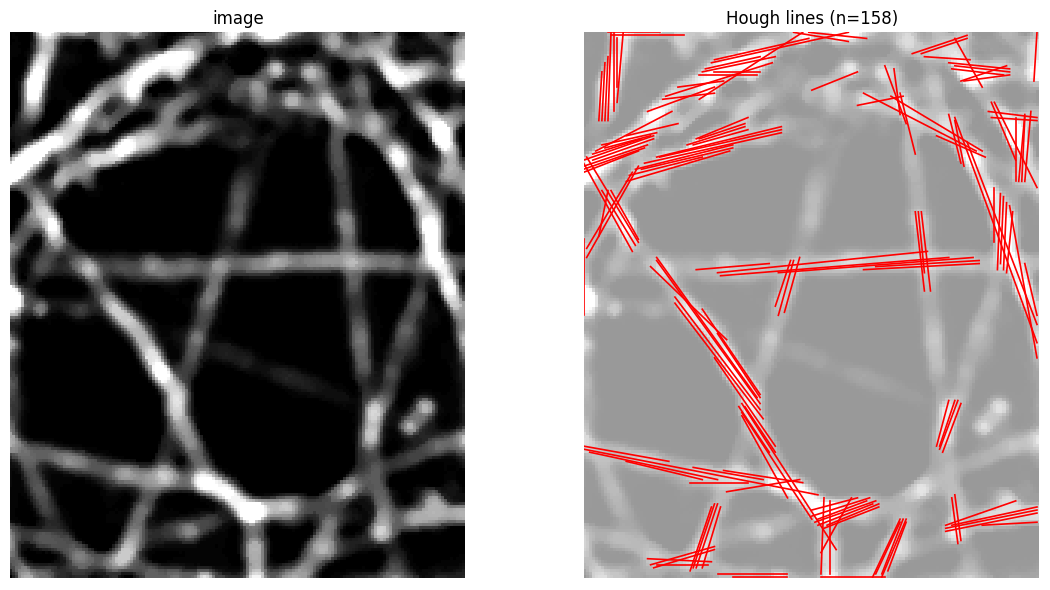

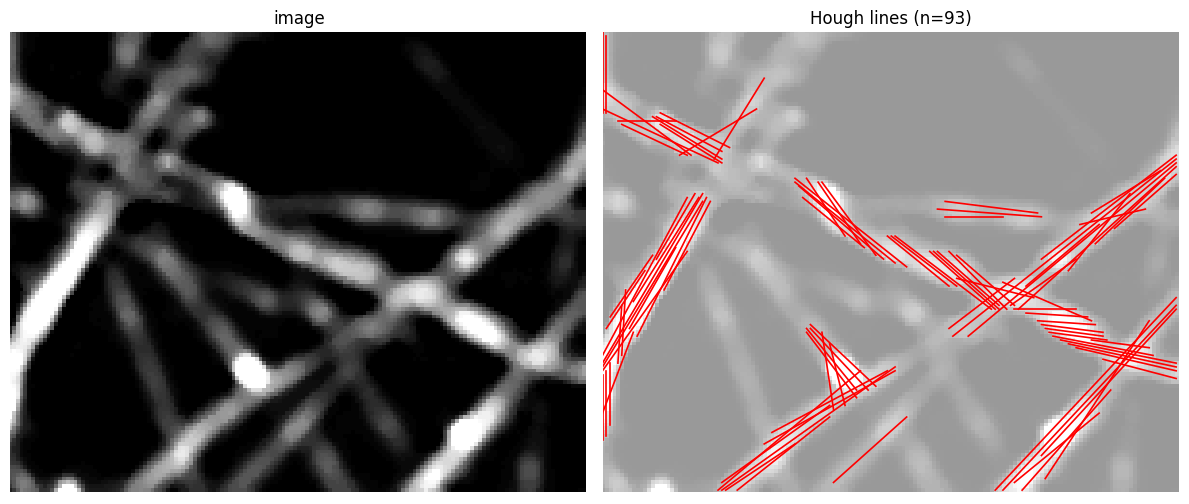

In [124]:

for patch in [patch_1, patch_2, patch_3]:
    patch_pre = preprocessing(patch[:,:,0])

    show_hough_lines(patch_pre, tophat_radius=6, threshold=10, line_length=15, line_gap=3)

# Segmentation

In [125]:
import numpy as np
from sklearn.cluster import KMeans

def kmeans_binary_mask(img):
    if img.ndim == 3:
        # standard luminance weights, no cv2 needed
        gray = img[..., :3] @ [0.114, 0.587, 0.299]  # assumes BGR order
    else:
        gray = img

    data = gray.reshape((-1, 1)).astype(np.float32)

    kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
    labels = kmeans.fit_predict(data)

    foreground = np.argmax(kmeans.cluster_centers_)
    mask = (labels == foreground).reshape(gray.shape).astype(np.uint8) * 255

    return mask

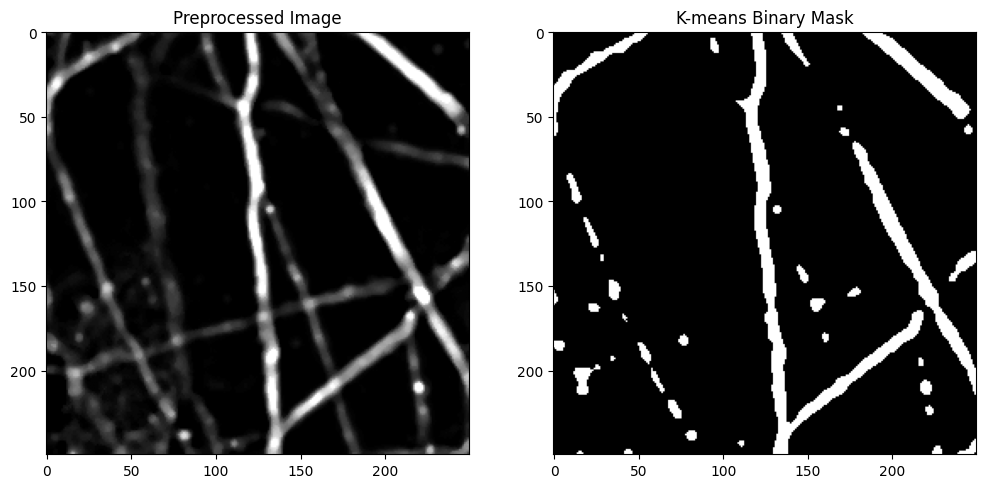

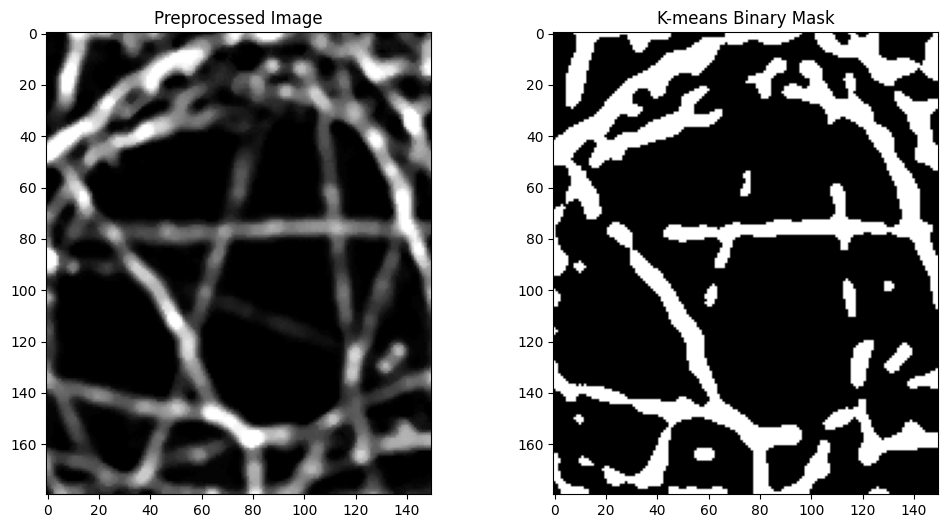

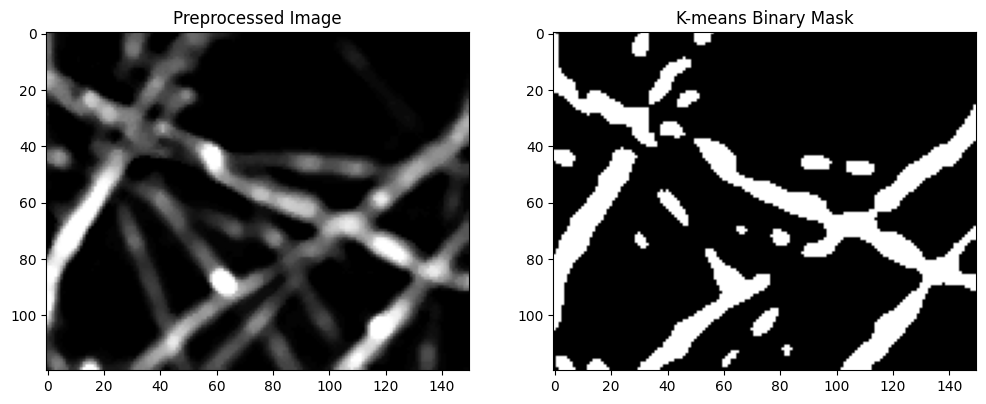

In [126]:
for patch in [patch_1, patch_2, patch_3]:
    patch_pre = preprocessing(patch[:,:,0])

    mask = kmeans_binary_mask(patch_pre)
    figure, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(patch_pre, cmap='gray')
    ax[0].set_title("Preprocessed Image")
    ax[1].imshow(mask, cmap='gray')
    ax[1].set_title("K-means Binary Mask")      
    

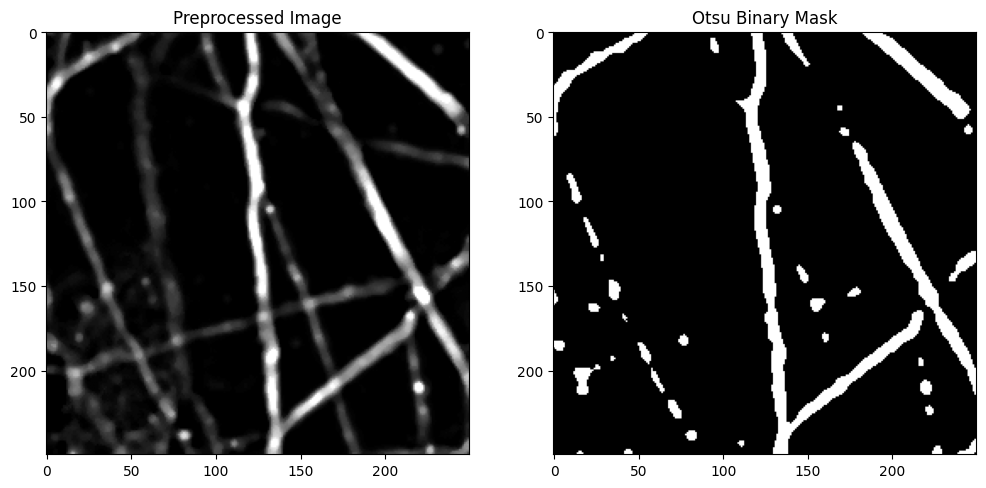

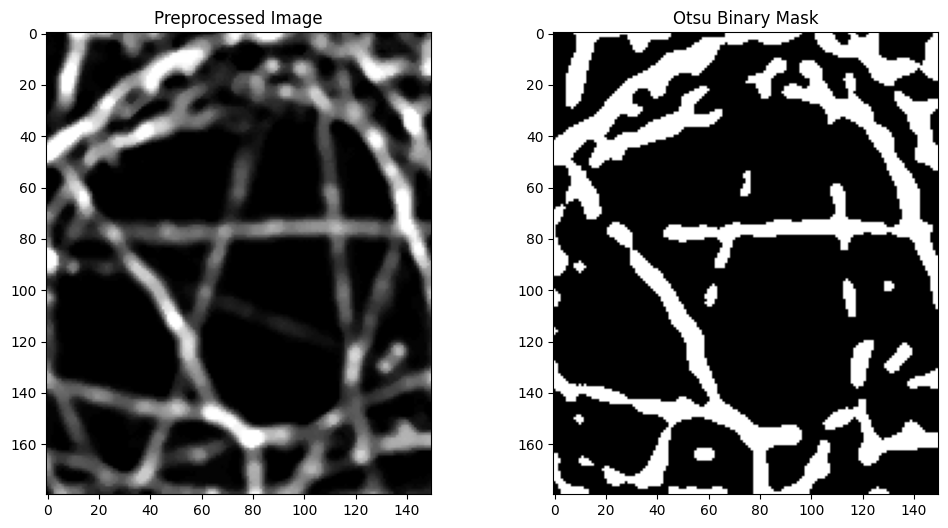

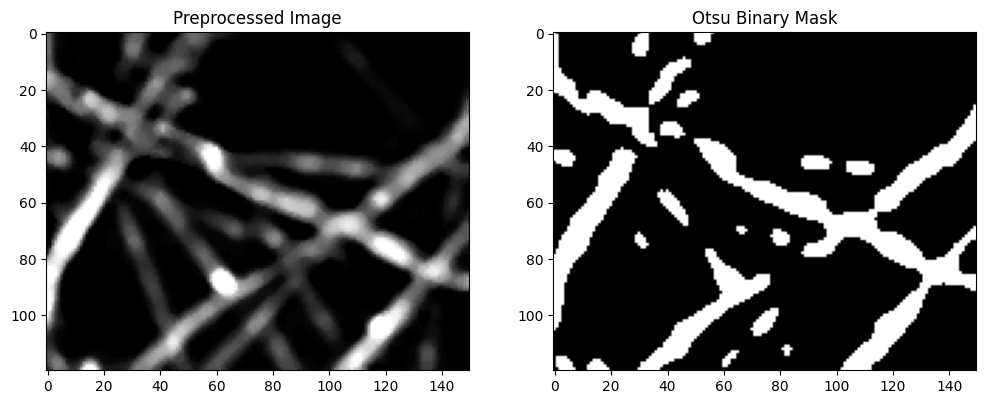

In [127]:
import numpy as np
from skimage.filters import threshold_otsu

def otsu_binary_mask(img):
    if img.ndim == 3:
        gray = img[..., :3] @ [0.114, 0.587, 0.299]  # BGR weights
    else:
        gray = img

    thresh = threshold_otsu(gray)
    mask = (gray > thresh).astype(np.uint8) * 255

    return mask

for patch in [patch_1, patch_2, patch_3]:
    patch_pre = preprocessing(patch[:,:,0])

    mask = otsu_binary_mask(patch_pre)
    figure, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(patch_pre, cmap='gray')
    ax[0].set_title("Preprocessed Image")
    ax[1].imshow(mask, cmap='gray')
    ax[1].set_title("Otsu Binary Mask")      
    

# Skeletonize after preprocessing

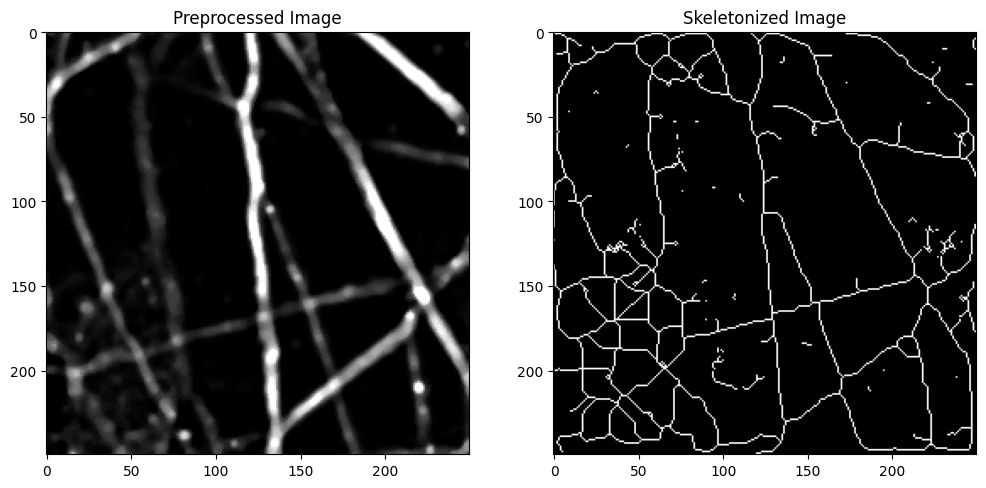

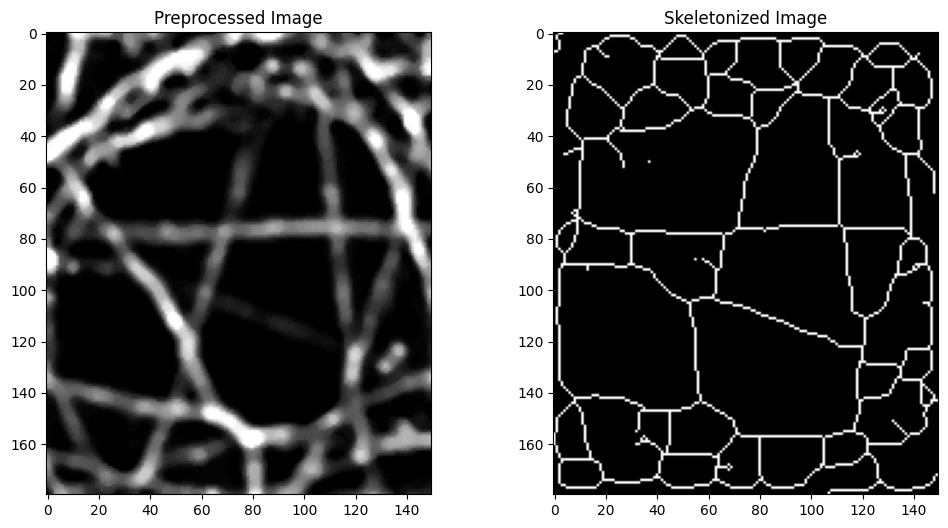

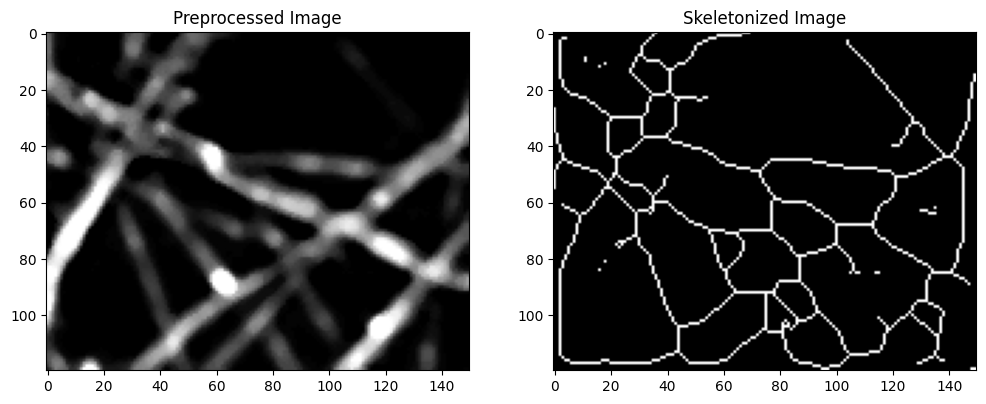

In [128]:

for patch in [patch_1, patch_2, patch_3]:
    patch_pre = preprocessing(patch[:,:,0])

    skeleton = skeletonize(patch_pre)
    figure, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(patch_pre, cmap='gray')            
    ax[1].imshow(skeleton, cmap='gray')
    ax[0].set_title("Preprocessed Image")
    ax[1].set_title("Skeletonized Image")